**本节课介绍了关于softmax回归模型的搭建和训练代码**

# 前置准备

## 导入包和库（torch库）

In [182]:
#导入包
import torch
from IPython import display
from d2l import torch as d2l

## 初始化参数

In [183]:
#输入维度应该是 28 * 28 = 784（就是说把一张 28 * 28 的图片展平成一个 784 * 1 的张量）
num_inputs = 784
#输出维度是 10 （也就是我们要获取机器对 10 个物体分别的预测概率）
num_outputs = 10
#这里相当于是说对于每组训练数据 x_1 ~ x_n，我们都可以列出一个线性回归模型的方程，对应一组 w, b
#那么总共就有 num_outputs = 10 个线性方程，对应 10 组 w, b

#初始化参数，使用整态分布
w = torch.normal(0, 0.01, size=(num_inputs, num_outputs), requires_grad=True)
b = torch.zeros(num_outputs, requires_grad=True)

## 定义 softmax 回归模型

In [184]:
#定义 softmax 函数用于归一化输出结果（也就是所有元素之和为 1 且每个元素非负）
#这样才能使用概率论、信息论的相关工具，而且该函数便于求导
#此处的输入是一个 1, 10 的张量（也就是机器学习的预测结果）
def softmax(O):
    #这里计算出来的是对每一个元素求指数，还是一个 1, 10 的张量
    O_exp = torch.exp(O)
    #然后对指数求和，得到分母。由于是对第二个维度求和，所以结果是一个 1, 1 的张量
    #这里使用了 keepdim 所以没有坍缩为一维张量，这也是为了最后一步使用广播机制做准备
    amount = O_exp.sum(1, keepdim= True)
    #使用广播机制让每一个元素除以分母，将输入的每一个分量归一化，得到概率
    return O_exp / amount

In [185]:
#定义我们的模型
#这里的输入是训练数据集 X，然后使用 y = softmax（X * w + b）输出一个 1，10 的预测向量 y 
#此处的方程与线性回归模型不同的地方在于由于输出维度变多了，需要使用 softmax() 函数进行归一化
def softmax_class(X):
    return softmax(torch.matmul(X.reshape((-1, w.shape[0])), w) + b)

In [186]:
#定义交叉熵损失函数
#由于已知交叉熵的计算公式，并且得到了推论：一个类别其独热编码真实向量与其预测向量的交叉熵就是对应类别的预测概率取负对数
#那么我们只要取出所有生成的预测向量对应的那个 1 所在下标的值就是对应类别的预测概率，再去负对数就好了
#因为一个 batch 有 256 个样本，所有所得交叉熵是一个 1 * 256 的张量
#这里的 true_y 其实是 labels
def cross_entropy(pre_y, true_y):
    return - torch.log(pre_y[list(range(len(pre_y))), true_y])

## 关于模型评估的方法

In [187]:
#定义一个函数来返回机器预测正确的样本的数量
#这里由于一批训练样本有 256 个，那么预测向量组成的张量就是 256 * 10 的
#而 labels 是 256 的一维张量，二者无法比较
#所以先取出概率最大的索引的下标组为预测值，看看它和对应的 labels 有几个相同
def accuracy(pre_y, true_y):
    #这里做了个判断，如果是概率张量而不是已经处理过的标号张量就将其使用 argmax() 处理得到每一行的最大值（按列去找）
    if len(pre_y.shape) > 1 and pre_y.shape[1] > 1:
        pre_y = pre_y.argmax(axis=1)
    #这里由于不清楚两者的基本数据类型是否相同，所以先对其采用强制类型转换再比较
    #比较过后输出的是 bool 变量，所以又要再转换类型
    cmp = (pre_y.type(true_y.dtype) == true_y).type(true_y.dtype)
    #所得 cmp 是一个和 true_y 数据类型相同的张量，可以使用 sum() 求预测正确的个数
    #因为后续要做除法判断正确率，所以这里设为 float，此函数输出一个标量
    return float(cmp.sum())

In [188]:
#定义一个实用类，便于求和
class Accumulator:  
    #构造器，指定数据数组元素的个数
    def __init__(self, n):
        self.data = [0.0] * n

    #让 data 数组里的每个元素加 args 的对应元素
    #这里 *args 是不定长参数，需要输入与 self.data 长度一致的参数个数才行
    def add(self, *args):
        self.data = [a + float(b) for a, b in zip(self.data, args)]

    #对组进行清零
    def reset(self):
        self.data = [0.0] * len(self.data)

    #重写方法 _getitem__ 使该类的实例在使用 [i] 求对应索引的元素时隐式调用该函数返回 slef.data[i]
    def __getitem__(self, idx):
        return self.data[idx]

In [189]:
#定义一个函数用测试数据评估模型的预测精度
def evaluate_accuracy(net, test_data_iter):
    #判断这个模型是不是 torch.nn.Module 类型的
    if isinstance(net, torch.nn.Module):
        #将其设为评估模式，不会对其进行更新
        net.eval()
    #创建一个计算求和的 Accumulator 类的实例
    #这里的 2 表示数组长度为 2，用于存放预测正确的个数和总样本个数
    metric = Accumulator(2)
    for X, y in test_data_iter:
        #将预测正确的个数和总样本个数进行累加
        #使用 numel() 是为了保障在任意维度的张量下都能正常使用
        metric.add(accuracy(net(X), y), y.numel())
    #返回正确率
    return metric[0] / metric[1]

# 模型的训练

## 训练效果可视化

In [190]:
#定义一个用于绘图的类
class Animator: 
    def __init__(self, xlabel=None, ylabel=None, legend=None, xlim=None,
                 ylim=None, xscale='linear', yscale='linear',
                 fmts=('-', 'm--', 'g-.', 'r:'), nrows=1, ncols=1,
                 figsize=(3.5, 2.5)):
        # 增量地绘制多条线
        if legend is None:
            legend = []
        d2l.use_svg_display()
        self.fig, self.axes = d2l.plt.subplots(nrows, ncols, figsize=figsize)
        if nrows * ncols == 1:
            self.axes = [self.axes, ]
        # 使用lambda函数捕获参数
        self.config_axes = lambda: d2l.set_axes(
            self.axes[0], xlabel, ylabel, xlim, ylim, xscale, yscale, legend)
        self.X, self.Y, self.fmts = None, None, fmts

    def add(self, x, y):
        # 向图表中添加多个数据点
        if not hasattr(y, "__len__"):
            y = [y]
        n = len(y)
        if not hasattr(x, "__len__"):
            x = [x] * n
        if not self.X:
            self.X = [[] for _ in range(n)]
        if not self.Y:
            self.Y = [[] for _ in range(n)]
        for i, (a, b) in enumerate(zip(x, y)):
            if a is not None and b is not None:
                self.X[i].append(a)
                self.Y[i].append(b)
        self.axes[0].cla()
        for x, y, fmt in zip(self.X, self.Y, self.fmts):
            self.axes[0].plot(x, y, fmt)
        self.config_axes()
        display.display(self.fig)
        display.clear_output(wait=True)

## 训练函数

In [191]:
#定义一个迭代周期函数完成训练
#此处仅使用一个批量的样本数据，完成一次训练并返回此次训练的损失与正确率
def one_train_epoch(net, train_iter, loss, trainer):
    if isinstance(net, torch.nn.Module):
        #开启训练模式
        net.train()
    #实例化，三个槽位，用于记录 损失、正确个数、样本总量
    metric = Accumulator(3)
    for X, y in train_iter:
        #计算损失
        loss_ = loss(net(X), y)
        #如果是 torch 框架下的直接使用内置函数
        if isinstance(trainer, torch.optim.Optimizer):
            #三步走：清零、求平均梯度、更新参数
            trainer.zero_grad()
            loss_.mean().backward()
            trainer.step()
        else:
            #如果不是该框架，就用定制好的迭代方案
            loss_.sum().backward()
            #这里的 X.shape[0] 其实就是 batch_size，二者相等
            d2l.sgd([w, b], lr, X.shape[0])
        #记录 损失、正确个数、样本总量
        metric.add(float(loss_.sum()), accuracy(net(X), y), y.numel())
    #返回损失率和正确率
    return metric[0]/metric[2], metric[1]/metric[2]

In [ ]:
#模型的训练 + 训练效果实时输出
def train(net, num_epochs, train_iter, test_iter, loss,  trainer): 
    animator = Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0.3, 0.9],
                        legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        #训练损失率与正确率
        train_loss, train_acc = one_train_epoch(net, train_iter, loss, trainer)
        #测试正确率
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, (train_loss, train_acc) + (test_acc,))
    #对于训练结果的测评
    #训练损失小于 0.5 正常，否则打印错误信息 train_loss
    assert train_loss < 0.5, train_loss
    #同理
    assert train_acc <= 1 and train_acc > 0.7, train_acc
    assert test_acc <= 1 and test_acc > 0.7, test_acc

## 初始化超参数

In [ ]:
#定义训练数据的批量
batch_size = 256
#训练数据迭代器
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

#学习率
lr = 0.1
#训练次数
num_epochs = 10
#模型
net = softmax_class #单层线性模型
#损失函数
loss = cross_entropy
#直接使用库中已有的训练方式，采用随机梯度下降
trainer = torch.optim.SGD([w, b], lr)

100.0%
100.0%
100.0%
100.0%


## 进行训练

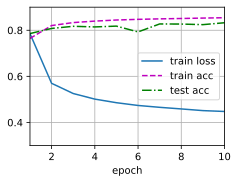

In [194]:

train(net, num_epochs, train_iter, test_iter, loss, trainer)

# 预测结果

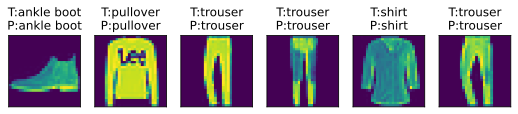

In [195]:
def predict(net, test_iter, num_data=6): 
    for X, y in test_iter:
        break
    trues = d2l.get_fashion_mnist_labels(y)
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = ['T:' + true +'\n' + 'P:' +pred for true, pred in zip(trues, preds)]
    d2l.show_images(
        X[0:num_data].reshape((num_data, 28, 28)), 1, num_data, titles=titles[0:num_data])

predict(net, test_iter)